# Butina clustering of the DRD2 compound set

Adapted from TeachOpenCADD talktorial T005 (compound clustering; Spriewald, Caswara, RodrÃ­guez-Guerra; Volkamer lab, CharitÃ©).

**Input:** `data/raw/drd2_curated_compounds.csv` with columns `CHEMBLid`, `pIC50`, `smiles`.

**Steps**

1. Load compounds. Keep the largest fragment (salt removal).
2. Generate Morgan fingerprints.
3. Compute the Tanimoto distance matrix (distance = 1 âˆ’ similarity).
4. Scan distance cutoffs and choose one.
5. Cluster with the Butina algorithm. The first member of each cluster is its centroid.
6. Inspect clusters and save the tables.

In [140]:
from pathlib import Path

from IPython.display import SVG
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.ML.Cluster import Butina

## Paths and parameters

In [141]:
# Resolve the repository root from the kernel working directory.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / ".git").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the repository root from the current directory.")
    PROJECT_ROOT = PROJECT_ROOT.parent

INPUT = PROJECT_ROOT / "data" / "raw" / "drd2_curated_compounds.csv"
TABLES = PROJECT_ROOT / "results" / "tables"
FIGURES = PROJECT_ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

MORGAN_RADIUS = 2
MORGAN_NBITS = 2048

CUTOFF = 0.4                          # Tanimoto distance cutoff (similarity >= 1 - cutoff)
CUTOFF_SCAN = [0.2, 0.3, 0.4, 0.5, 0.6]
N_EXAMPLES = 10                       # molecules drawn per example grid

## Load compounds

SMILES are parsed with RDKit. Counterions are removed by keeping the largest fragment. Unparsable SMILES are dropped.

In [142]:
def load_dataset(path):
    """Read the curated table, strip salts, and drop unparsable SMILES."""
    df = pd.read_csv(path, usecols=["CHEMBLid", "pIC50", "smiles"])
    chooser = rdMolStandardize.LargestFragmentChooser()
    mols = []
    for smiles in df["smiles"]:
        mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) else None
        mols.append(chooser.choose(mol) if mol is not None else None)
    df["mol"] = mols
    n_bad = df["mol"].isna().sum()
    if n_bad:
        print(f"Dropping {n_bad} compounds with unparsable SMILES")
    return df.dropna(subset=["mol"]).reset_index(drop=True)


df = load_dataset(INPUT)
print(f"Compounds in dataset: {len(df)}")
df.drop(columns="mol").head()

Compounds in dataset: 435


[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Fragment: CC(C)[C@@]1(NC(=O)[C@@H]2C[C@@H]3c4cccc5[nH]cc(c45)C[C@H]3N(C)C2)O[C@@]2(O)[C@@H]3CCCN3C(=O)[C@H](Cc3ccccc3)N2C1=O
[09:36:00] New largest fragment: CC(C)[C@@]1(NC(=O)[C@@H]2C[C@@H]3c4cccc5[nH]cc(c45)C[C@H]3N(C)C2)O[C@@]2(O)[C@@H]3CCCN3C(=O)[C@H](Cc3ccccc3)N2C1=O (86)
[09:36:00] Fragment: CS(=O)(=O)O
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36:00] Running LargestFragmentChooser
[09:36

,CHEMBLid,pIC50,smiles
0,CHEMBL567,9.522879,OCCN1CCN(CCCN2c3ccccc3Sc3ccc(Cl)cc32)CC1
1,CHEMBL6004129,9.008774,COc1ccccc1N1CCN(CCCCOc2ccc3c(c2)NC(=O)CO3)CC1
2,CHEMBL5851827,8.974694,O=C1CCc2cc(CCCCN3CCN(c4cccc5sc(F)cc45)CC3)ccc2N1
3,CHEMBL8514,8.958607,CC(C)(C)[C@]1(O)CCN2C[C@H]3c4ccccc4CCc4cccc(c4...
4,CHEMBL3885419,8.958607,CC(C)(C)[C@]1(O)CCN2C[C@@H]3c4ccccc4CCc4cccc(c...


## Fingerprints

In [143]:
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=MORGAN_RADIUS, fpSize=MORGAN_NBITS
)
fps = [morgan_generator.GetFingerprint(m) for m in df["mol"]]
print(f"Fingerprints: {len(fps)}, length {len(fps[0])}")

Fingerprints: 435, length 2048


## Tanimoto distance matrix

Butina clustering takes the lower triangle of the distance matrix as a flat list. For *n* molecules the list has *n(nâˆ’1)/2* elements. The matrix is computed once and reused for every cutoff.

In [144]:
def tanimoto_distance_matrix(fp_list):
    """Lower triangle of the Tanimoto distance matrix as a flat list."""
    distances = []
    for i in range(1, len(fp_list)):
        similarities = DataStructs.BulkTanimotoSimilarity(fp_list[i], fp_list[:i])
        distances.extend([1 - x for x in similarities])
    return distances


dist_matrix = tanimoto_distance_matrix(fps)
n = len(fps)
print(f"Elements in distance list: {len(dist_matrix)} (n(n-1)/2 = {n * (n - 1) // 2})")

Elements in distance list: 94395 (n(n-1)/2 = 94395)


In [145]:
def cluster_from_distances(distances, n_mols, cutoff):
    """Butina clustering. Returns clusters sorted by size, largest first.
    The first index of each cluster is its centroid."""
    clusters = Butina.ClusterData(distances, n_mols, cutoff, isDistData=True)
    return sorted(clusters, key=len, reverse=True)

## Cutoff scan

A higher distance cutoff merges more molecules into fewer clusters. A lower cutoff produces more clusters and singletons.

In [146]:
rows = []
for cutoff in CUTOFF_SCAN:
    scan_clusters = cluster_from_distances(dist_matrix, len(fps), cutoff)
    sizes = [len(c) for c in scan_clusters]
    rows.append({
        "cutoff": cutoff,
        "n_clusters": len(scan_clusters),
        "singletons": sum(s == 1 for s in sizes),
        "clusters_gt5": sum(s > 5 for s in sizes),
        "largest_cluster": max(sizes),
    })
scan = pd.DataFrame(rows)
scan.to_csv(TABLES / "butina_cutoff_scan.csv", index=False)
scan

,cutoff,n_clusters,singletons,clusters_gt5,largest_cluster
0,0.2,335,275,3,8
1,0.3,246,164,12,11
2,0.4,178,108,18,30
3,0.5,131,75,22,60
4,0.6,95,53,19,90


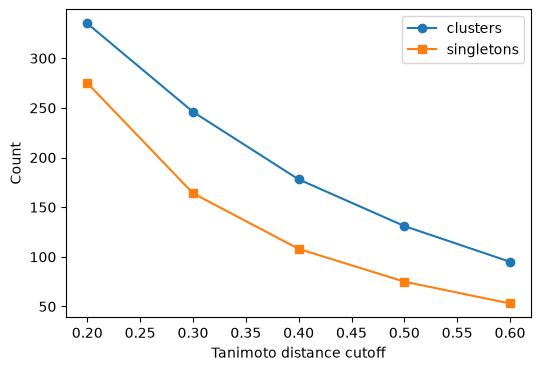

In [147]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(scan["cutoff"], scan["n_clusters"], "o-", label="clusters")
ax.plot(scan["cutoff"], scan["singletons"], "s-", label="singletons")
ax.set_xlabel("Tanimoto distance cutoff")
ax.set_ylabel("Count")
ax.legend()
fig.savefig(FIGURES / "butina_cutoff_scan.png", dpi=300, bbox_inches="tight")
plt.show()

## Clustering at the chosen cutoff

Set `CUTOFF` in the parameter cell to the value selected from the scan.

In [148]:
clusters = cluster_from_distances(dist_matrix, len(fps), CUTOFF)
sizes = [len(c) for c in clusters]

print(f"Cutoff: {CUTOFF:.2f} (similarity >= {1 - CUTOFF:.2f})")
print(f"Total clusters: {len(clusters)} from {len(fps)} molecules")
print(f"Singletons: {sum(s == 1 for s in sizes)}")
print(f"Clusters with >5 compounds: {sum(s > 5 for s in sizes)}")
print(f"Clusters with >25 compounds: {sum(s > 25 for s in sizes)}")
print(f"Largest cluster: {sizes[0]} compounds")

Cutoff: 0.40 (similarity >= 0.60)
Total clusters: 178 from 435 molecules
Singletons: 108
Clusters with >5 compounds: 18
Clusters with >25 compounds: 1
Largest cluster: 30 compounds


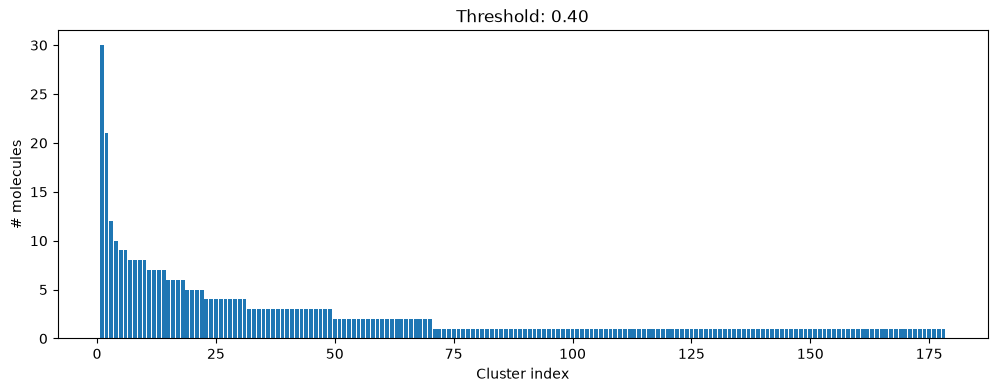

In [149]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(1, len(clusters) + 1), sizes)
ax.set_xlabel("Cluster index")
ax.set_ylabel("# molecules")
ax.set_title(f"Threshold: {CUTOFF:.2f}")
fig.savefig(FIGURES / f"butina_cluster_sizes_cutoff_{CUTOFF:.2f}.png", dpi=300, bbox_inches="tight")
plt.show()

## Cluster assignments

In [150]:
df["cluster_id"] = -1
df["is_centroid"] = False
for cluster_id, members in enumerate(clusters, start=1):
    df.loc[list(members), "cluster_id"] = cluster_id
    df.loc[members[0], "is_centroid"] = True
df["cluster_size"] = df.groupby("cluster_id")["cluster_id"].transform("size")

centroid_ids = df[df["is_centroid"]].set_index("cluster_id")["CHEMBLid"]
summary = (
    df.groupby("cluster_id")
    .agg(size=("CHEMBLid", "size"),
         mean_pIC50=("pIC50", "mean"),
         min_pIC50=("pIC50", "min"),
         max_pIC50=("pIC50", "max"))
    .reset_index()
)
summary["centroid"] = summary["cluster_id"].map(centroid_ids)
summary.head(10)

,cluster_id,size,mean_pIC50,min_pIC50,max_pIC50,centroid
0,1,30,7.716009,6.667562,8.735182,CHEMBL5984307
1,2,21,7.323588,6.115771,8.698970,CHEMBL1202215
2,3,12,7.702073,6.017729,8.583359,CHEMBL4102670
3,4,10,6.534915,5.638272,7.585027,CHEMBL3323011
4,5,9,5.093940,4.795880,5.337242,CHEMBL1700053
5,6,9,6.667923,4.958607,7.638272,CHEMBL42
6,7,8,5.627133,5.048711,6.110138,CHEMBL2016614
7,8,8,5.656434,5.184422,6.737549,CHEMBL3134063
8,9,8,5.689620,5.161151,6.853872,CHEMBL259776
9,10,8,7.160751,6.346787,7.638272,CHEMBL302183


## Example molecules

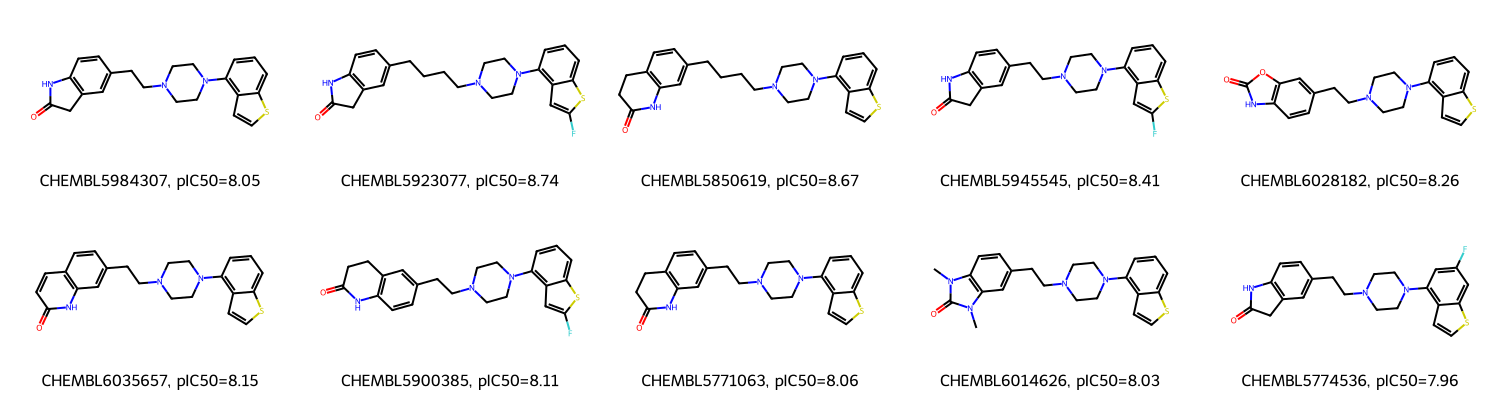

In [151]:
def draw_molecules(indices, legends, path, per_row=5):
    image_svg = Draw.MolsToGridImage(
        [df["mol"][i] for i in indices],
        legends=legends,
        molsPerRow=per_row,
        subImgSize=(300, 200),
        useSVG=True,
    )
    svg_text = image_svg if isinstance(image_svg, str) else image_svg.data
    path = Path(path).with_suffix(".svg")
    path.write_text(svg_text, encoding="utf-8")
    return SVG(svg_text)


# First molecules of the largest cluster (first entry is the centroid)
members = clusters[0][:N_EXAMPLES]
legends = [f"{df['CHEMBLid'][i]}, pIC50={df['pIC50'][i]:.2f}" for i in members]
draw_molecules(members, legends, FIGURES / "butina_largest_cluster.svg")

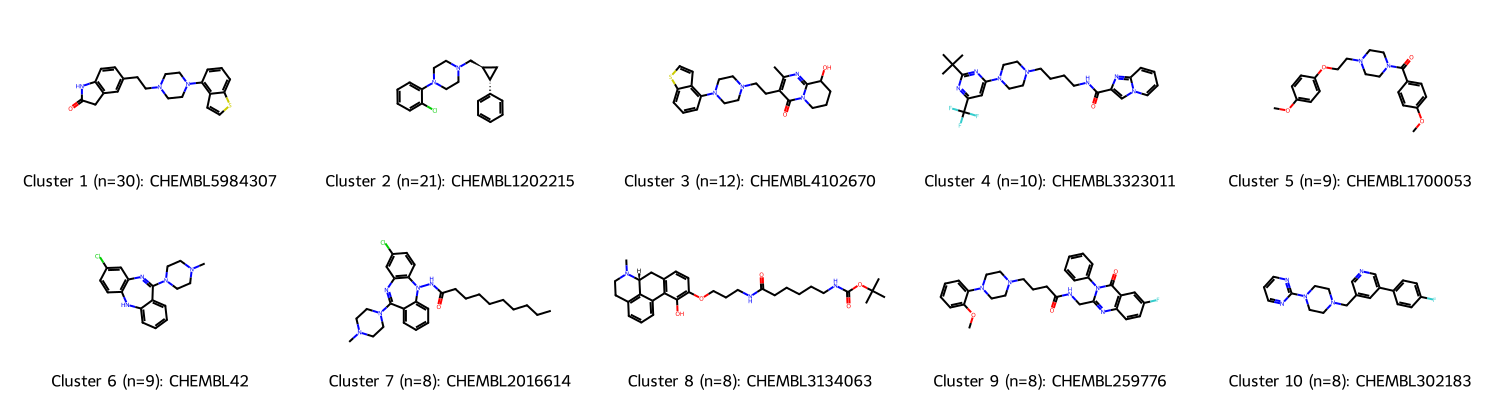

In [152]:
# Centroids of the largest clusters
centroids = [c[0] for c in clusters[:N_EXAMPLES]]
legends = [
    f"Cluster {k + 1} (n={len(clusters[k])}): {df['CHEMBLid'][i]}"
    for k, i in enumerate(centroids)
]
draw_molecules(centroids, legends, FIGURES / "butina_cluster_centroids.svg")

## Intra-cluster Tanimoto similarity

Pairwise similarity within each of the largest clusters (clusters with at least two members).

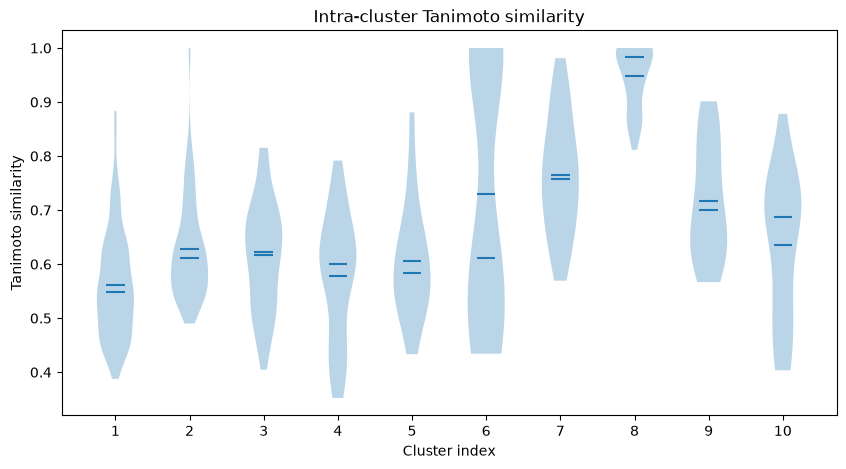

In [153]:
def intra_tanimoto(fps_clusters):
    """Pairwise Tanimoto similarities within each cluster."""
    return [[1 - x for x in tanimoto_distance_matrix(c)] for c in fps_clusters]


top = [c for c in clusters if len(c) > 1][:10]
intra_sim = intra_tanimoto([[fps[i] for i in c] for c in top])

fig, ax = plt.subplots(figsize=(10, 5))
positions = list(range(1, len(top) + 1))
ax.violinplot(intra_sim, positions, showmeans=True, showmedians=True, showextrema=False)
ax.set_xticks(positions)
ax.set_xlabel("Cluster index")
ax.set_ylabel("Tanimoto similarity")
ax.set_title("Intra-cluster Tanimoto similarity")
fig.savefig(FIGURES / "butina_intra_cluster_similarity.png", dpi=300, bbox_inches="tight")
plt.show()

## Save tables

In [154]:
cols = ["CHEMBLid", "pIC50", "smiles", "cluster_id", "cluster_size", "is_centroid"]
df.sort_values(["cluster_id", "pIC50"], ascending=[True, False])[cols].to_csv(
    TABLES / "butina_clusters.csv", index=False
)
summary.to_csv(TABLES / "butina_cluster_summary.csv", index=False)
print(f"Saved tables to {TABLES}")

Saved tables to C:\Users\manup\Documents\Leiden Universiteit\LUMC\Advanced Computational Methods in Drug Discovery\Mini-Research\drd2-antagonist-ml-docking\results\tables
